# Result 10：LC3 肺癌样本中 TMCN_S1P_Axis 肿瘤内部功能异质性分析

本 notebook 的核心目的不是评价整个样本的二分类 ARI，而是围绕一个更适合 LC3 的问题：

> 在病理注释为肿瘤的区域内部，TuMeNiche 是否识别出了一个具有独立功能特征的 `TMCN_S1P_Axis` 代谢生态位？

因此主比较组严格定义为：

- **目标组**：`Pathology_Tumor` 内部的 `TMCN_S1P_Axis`
- **对照组**：`Pathology_Tumor` 内部除 `TMCN_S1P_Axis` 之外的所有区域

这样可以检验：`TMCN_S1P_Axis` 是否代表肿瘤内部一个与 S1P 脂质信号、内皮血管生成、免疫趋化、炎症信号等相关的功能性亚生态位。

In [2]:
# =========================================================
# Cell 1: 全局路径与参数配置
# =========================================================
import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

# -----------------------------
# 样本与目标生态位
# -----------------------------
SAMPLE_NAME = "LC3"
TARGET_NICHE = "TMCN_S1P_Axis"

# -----------------------------
# 输入路径
# -----------------------------
ORIGINAL_H5AD = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/lung_cancer_and_kidney_cancer/LC3.h5ad"
FINAL_H5AD = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/lung_cancer_and_kidney_cancer/LC3/SpaCET_And_My/lung_cancer_and_kidney_cancer_LC3_NicheCompassAndmy_Final.h5ad"
SPACET_CSV = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/SpaCET_R_Result/lung_cancer_and_kidney_cancer/LC3/LC3_CellFractions.csv"
GMT_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB"

# -----------------------------
# 输出路径
# -----------------------------
SAVE_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis"
FIG_DIR = os.path.join(SAVE_DIR, "figures")
TABLE_DIR = os.path.join(SAVE_DIR, "tables")
DEG_DIR = os.path.join(SAVE_DIR, "DEG")
ENRICH_DIR = os.path.join(SAVE_DIR, "enrichment")

for d in [SAVE_DIR, FIG_DIR, TABLE_DIR, DEG_DIR, ENRICH_DIR]:
    os.makedirs(d, exist_ok=True)

# -----------------------------
# S1P 轴定义
# -----------------------------
S1P_SOURCE_GENES = ["SPHK1", "SPHK2", "SPNS2"]
S1P_TARGET_GENES = ["S1PR1", "S1PR2", "S1PR3"]
S1P_AXIS_GENES = S1P_SOURCE_GENES + S1P_TARGET_GENES

# 结果解释时重点关注的功能关键词
FUNCTION_KEYWORDS = [
    "ANGIOGENESIS", "ENDOTHELIAL", "VASCUL", "BLOOD_VESSEL", "VESSEL",
    "LEUKOCYTE", "LYMPHOCYTE", "CHEMOTAXIS", "CHEMOKINE", "IMMUNE",
    "INFLAMMATORY", "CYTOKINE", "NF_KB", "NFKB", "PI3K", "AKT", "MAPK",
    "MIGRATION", "CELL_MIGRATION", "T_CELL", "MACROPHAGE"
]

print("SAVE_DIR:", SAVE_DIR)
print("TARGET_NICHE:", TARGET_NICHE)

SAVE_DIR: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis
TARGET_NICHE: TMCN_S1P_Axis


In [3]:
# =========================================================
# Cell 2: 读取原始全基因表达矩阵 + 最终 TuMeNiche 结果
# 说明：DEG 使用原始 LC3.h5ad 的全基因表达矩阵，标签来自最终 h5ad。
# =========================================================
print("正在读取原始 LC3 h5ad...")
adata_raw = sc.read_h5ad(ORIGINAL_H5AD)
print("原始数据:", adata_raw)

print("\n正在读取最终 TuMeNiche h5ad...")
adata_final = sc.read_h5ad(FINAL_H5AD)
print("最终结果:", adata_final)

# 统一 gene symbol 字符串格式
adata_raw.var_names = adata_raw.var_names.astype(str)
adata_final.var_names = adata_final.var_names.astype(str)

# spot 对齐
common_spots = adata_raw.obs_names.intersection(adata_final.obs_names)
print(f"\n共同 spots 数量: {len(common_spots)}")
if len(common_spots) == 0:
    raise ValueError("原始 h5ad 与最终 h5ad 没有共同 spot，请检查 spot id。")

adata = adata_raw[common_spots].copy()
adata_final_sub = adata_final[common_spots].copy()

# 合并关键标签列
label_cols = [
    "ground_truth",
    "Pathology_Binary_ARI",
    "Level1_Macro_Region",
    "Level2_Micro_Niche",
]

for col in label_cols:
    if col in adata_final_sub.obs.columns:
        adata.obs[col] = adata_final_sub.obs[col].astype(str).values
    else:
        print(f"⚠️ 最终 h5ad 中没有 {col}，后续会尝试自动生成或跳过。")

# 如果最终 h5ad 没有 Pathology_Binary_ARI，则根据 ground_truth 自动生成
if "Pathology_Binary_ARI" not in adata.obs.columns:
    if "ground_truth" not in adata.obs.columns and "ground_truth" in adata_raw.obs.columns:
        adata.obs["ground_truth"] = adata_raw.obs.loc[adata.obs_names, "ground_truth"].astype(str).values
    gt_map_int = {"TUM": 1, "NOR": 0, "TLS": 0, "INFL": 0}
    gt_map_str = {1: "Pathology_Tumor", 0: "Pathology_Non_Tumor"}
    patho_clean = adata.obs["ground_truth"].astype(str).str.strip()
    pathology_numeric = patho_clean.map(gt_map_int)
    adata.obs["Pathology_Binary_ARI"] = pathology_numeric.map(gt_map_str).fillna("Unmapped_for_ARI")

# 合并 SpaCET 细胞组成结果：优先从原始 adata.obs；如果不存在，尝试 CSV
if os.path.exists(SPACET_CSV):
    spacet_df = pd.read_csv(SPACET_CSV, index_col=0)
    spacet_common = adata.obs_names.intersection(spacet_df.index)
    if len(spacet_common) > 0:
        spacet_df = spacet_df.reindex(adata.obs_names)
        for c in spacet_df.columns:
            if c not in adata.obs.columns:
                adata.obs[c] = spacet_df[c].values
        print(f"已从 SpaCET CSV 合并细胞组成列: {spacet_df.shape[1]} 个")

# 类型标准化
adata.obs["Pathology_Binary_ARI"] = pd.Categorical(
    adata.obs["Pathology_Binary_ARI"].astype(str),
    categories=["Pathology_Tumor", "Pathology_Non_Tumor", "Unmapped_for_ARI"],
    ordered=False,
)

if "Level2_Micro_Niche" not in adata.obs.columns:
    raise KeyError("缺少 Level2_Micro_Niche，无法进行 TMCN_S1P_Axis 分析。")

level2_categories = pd.Series(adata.obs["Level2_Micro_Niche"].astype(str)).dropna().unique().tolist()
adata.obs["Level2_Micro_Niche"] = pd.Categorical(
    adata.obs["Level2_Micro_Niche"].astype(str),
    categories=level2_categories,
    ordered=False,
)

print("\nPathology_Binary_ARI 统计:")
print(adata.obs["Pathology_Binary_ARI"].value_counts())
print("\nLevel2_Micro_Niche 统计:")
print(adata.obs["Level2_Micro_Niche"].value_counts())

if TARGET_NICHE not in adata.obs["Level2_Micro_Niche"].astype(str).unique():
    raise ValueError(f"没有在 Level2_Micro_Niche 中找到目标生态位: {TARGET_NICHE}")

正在读取原始 LC3 h5ad...


原始数据: AnnData object with n_obs × n_vars = 2120 × 17845
    obs: 'in_tissue', 'x_array', 'y_array', 'x_pixel', 'y_pixel', 'manual_anno', 'manual_anno_tls', 'aestetik_manual_anno', 'aestetik_manual_anno_tls', 'ground_truth', 'blur_score', 'Ground_Truth_Binary', 'Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage M1', 'Macrophage M2', 'Macrophage other'
    var: 'gene_ids', 'feature_types', 'gene_name'
    uns: 'Ground_Truth_Binary_colors', 'remove_UNASSIGNED_info', 'spatial'
    obsm: 'spatial'

正在读取最终 TuMeNiche h5ad...
最终结果: AnnData object with n_obs × n_vars = 2120 × 3044
    obs: 'in_tissue', 'x_a

## 实验设计修正说明

本分析不使用整体 ARI 作为 Result 10 的论据。因为本 Result 关注的是：

> TuMeNiche 是否能在病理肿瘤区域内部进一步识别出一个具有功能差异的 S1P 代谢生态位。

因此下面定义的核心比较为：

- `S1P_in_Pathology_Tumor`：病理肿瘤区域中的 `TMCN_S1P_Axis`
- `Tumor_non_S1P`：病理肿瘤区域中除 `TMCN_S1P_Axis` 外的其他 spots

后续 DEG、富集分析、细胞组成比较都围绕这两个组展开。

In [4]:
# =========================================================
# Cell 3: 定义“病理肿瘤区域内部”的核心比较组
# =========================================================
pathology_tumor_mask = adata.obs["Pathology_Binary_ARI"].astype(str) == "Pathology_Tumor"
target_mask_all = adata.obs["Level2_Micro_Niche"].astype(str) == TARGET_NICHE

target_in_tumor_mask = pathology_tumor_mask & target_mask_all
tumor_non_s1p_mask = pathology_tumor_mask & (~target_mask_all)

adata.obs["Result10_Group"] = "Not_Used_in_Core_Comparison"
adata.obs.loc[target_in_tumor_mask, "Result10_Group"] = "S1P_in_Pathology_Tumor"
adata.obs.loc[tumor_non_s1p_mask, "Result10_Group"] = "Tumor_non_S1P"
adata.obs["Result10_Group"] = pd.Categorical(
    adata.obs["Result10_Group"],
    categories=["S1P_in_Pathology_Tumor", "Tumor_non_S1P", "Not_Used_in_Core_Comparison"],
    ordered=True,
)

# 用于全切片右图高亮
adata.obs["Highlight_TMCN_S1P_Axis"] = np.where(target_mask_all, TARGET_NICHE, "Other_Spots")
adata.obs["Highlight_TMCN_S1P_Axis"] = pd.Categorical(
    adata.obs["Highlight_TMCN_S1P_Axis"],
    categories=[TARGET_NICHE, "Other_Spots"],
    ordered=True,
)

# 用于病理肿瘤内部比较图
adata.obs["Tumor_Internal_S1P_Comparison"] = "Not_Pathology_Tumor"
adata.obs.loc[tumor_non_s1p_mask, "Tumor_Internal_S1P_Comparison"] = "Tumor_non_S1P"
adata.obs.loc[target_in_tumor_mask, "Tumor_Internal_S1P_Comparison"] = "S1P_in_Pathology_Tumor"
adata.obs["Tumor_Internal_S1P_Comparison"] = pd.Categorical(
    adata.obs["Tumor_Internal_S1P_Comparison"],
    categories=["S1P_in_Pathology_Tumor", "Tumor_non_S1P", "Not_Pathology_Tumor"],
    ordered=True,
)

summary_counts = pd.DataFrame({
    "metric": [
        "total_spots",
        "pathology_tumor_spots",
        "target_niche_all_spots",
        "target_niche_in_pathology_tumor_spots",
        "tumor_non_s1p_spots",
        "target_niche_tumor_overlap_fraction"
    ],
    "value": [
        adata.n_obs,
        int(pathology_tumor_mask.sum()),
        int(target_mask_all.sum()),
        int(target_in_tumor_mask.sum()),
        int(tumor_non_s1p_mask.sum()),
        float(target_in_tumor_mask.sum() / max(target_mask_all.sum(), 1))
    ]
})
summary_counts.to_csv(os.path.join(TABLE_DIR, "Result10_group_definition_summary.csv"), index=False, encoding="utf-8-sig")

print(summary_counts)
print("\nResult10_Group 统计:")
print(adata.obs["Result10_Group"].value_counts())

if target_in_tumor_mask.sum() < 5:
    raise ValueError("病理肿瘤区域内的 TMCN_S1P_Axis spots 太少，不建议进行 DEG。")
if tumor_non_s1p_mask.sum() < 5:
    raise ValueError("病理肿瘤区域内非 S1P spots 太少，不建议作为对照组。")

                                  metric   value
0                            total_spots  2120.0
1                  pathology_tumor_spots   772.0
2                 target_niche_all_spots   312.0
3  target_niche_in_pathology_tumor_spots   312.0
4                    tumor_non_s1p_spots   460.0
5    target_niche_tumor_overlap_fraction     1.0

Result10_Group 统计:
Not_Used_in_Core_Comparison    1348
Tumor_non_S1P                   460
S1P_in_Pathology_Tumor          312
Name: Result10_Group, dtype: int64


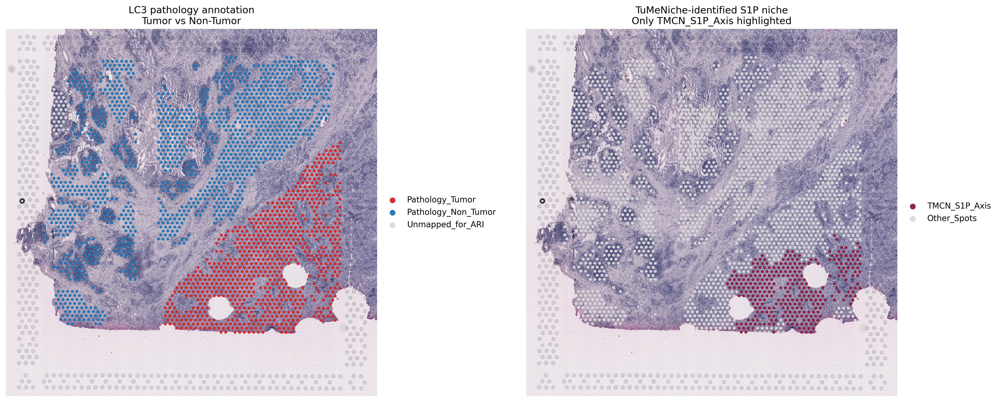

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/Figure10A_Pathology_vs_TMCN_S1P_Axis_highlight.png


In [5]:
# =========================================================
# Cell 4: Figure 10A - 左病理二分类，右只高亮 TMCN_S1P_Axis
# 严格沿用原 LC3 notebook 的 Squidpy 可视化方式：不传 palette=dict，而写入 adata.uns["xxx_colors"]。
# =========================================================
import squidpy as sq

# 病理二分类配色
pathology_categories = ["Pathology_Tumor", "Pathology_Non_Tumor", "Unmapped_for_ARI"]
pathology_palette = {
    "Pathology_Tumor": "#d62728",
    "Pathology_Non_Tumor": "#1f77b4",
    "Unmapped_for_ARI": "#d9d9d9",
}
adata.obs["Pathology_Binary_ARI"] = pd.Categorical(
    adata.obs["Pathology_Binary_ARI"].astype(str),
    categories=pathology_categories,
    ordered=False,
)
adata.uns["Pathology_Binary_ARI_colors"] = [pathology_palette[x] for x in pathology_categories]

# S1P 高亮配色
highlight_categories = [TARGET_NICHE, "Other_Spots"]
highlight_palette = {
    TARGET_NICHE: "#8c1d40",
    "Other_Spots": "#d9d9d9",
}
adata.obs["Highlight_TMCN_S1P_Axis"] = pd.Categorical(
    adata.obs["Highlight_TMCN_S1P_Axis"].astype(str),
    categories=highlight_categories,
    ordered=True,
)
adata.uns["Highlight_TMCN_S1P_Axis_colors"] = [highlight_palette[x] for x in highlight_categories]

library_id = list(adata.uns["spatial"].keys())[0]
fig, axs = plt.subplots(1, 2, figsize=(18, 7), dpi=300)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color="Pathology_Binary_ARI",
    size=10,
    alpha=0.95,
    title="LC3 pathology annotation\nTumor vs Non-Tumor",
    frameon=False,
    legend_loc="right margin",
    ax=axs[0],
)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color="Highlight_TMCN_S1P_Axis",
    size=10,
    alpha=0.95,
    title="TuMeNiche-identified S1P niche\nOnly TMCN_S1P_Axis highlighted",
    frameon=False,
    legend_loc="right margin",
    ax=axs[1],
)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "Figure10A_Pathology_vs_TMCN_S1P_Axis_highlight.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()
print("Figure saved:", fig_path)

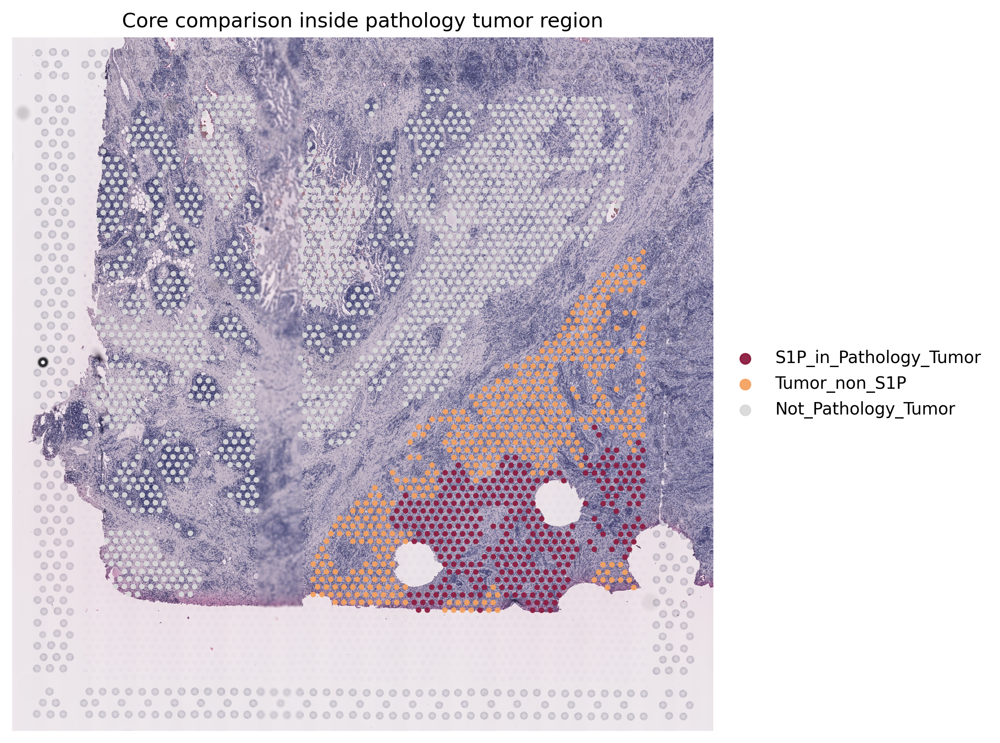

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/Figure10B_Tumor_internal_S1P_vs_nonS1P_comparison_group.png


In [6]:
# =========================================================
# Cell 5: 可选辅助图 - 病理肿瘤内部 S1P vs 非 S1P 区域
# 该图用于明确核心比较组，非病理肿瘤区域统一灰色。
# =========================================================
comparison_categories = ["S1P_in_Pathology_Tumor", "Tumor_non_S1P", "Not_Pathology_Tumor"]
comparison_palette = {
    "S1P_in_Pathology_Tumor": "#8c1d40",
    "Tumor_non_S1P": "#f4a261",
    "Not_Pathology_Tumor": "#d9d9d9",
}
adata.obs["Tumor_Internal_S1P_Comparison"] = pd.Categorical(
    adata.obs["Tumor_Internal_S1P_Comparison"].astype(str),
    categories=comparison_categories,
    ordered=True,
)
adata.uns["Tumor_Internal_S1P_Comparison_colors"] = [comparison_palette[x] for x in comparison_categories]

fig, ax = plt.subplots(1, 1, figsize=(8, 7), dpi=300)
sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color="Tumor_Internal_S1P_Comparison",
    size=10,
    alpha=0.95,
    title="Core comparison inside pathology tumor region",
    frameon=False,
    legend_loc="right margin",
    ax=ax,
)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "Figure10B_Tumor_internal_S1P_vs_nonS1P_comparison_group.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()
print("Figure saved:", fig_path)

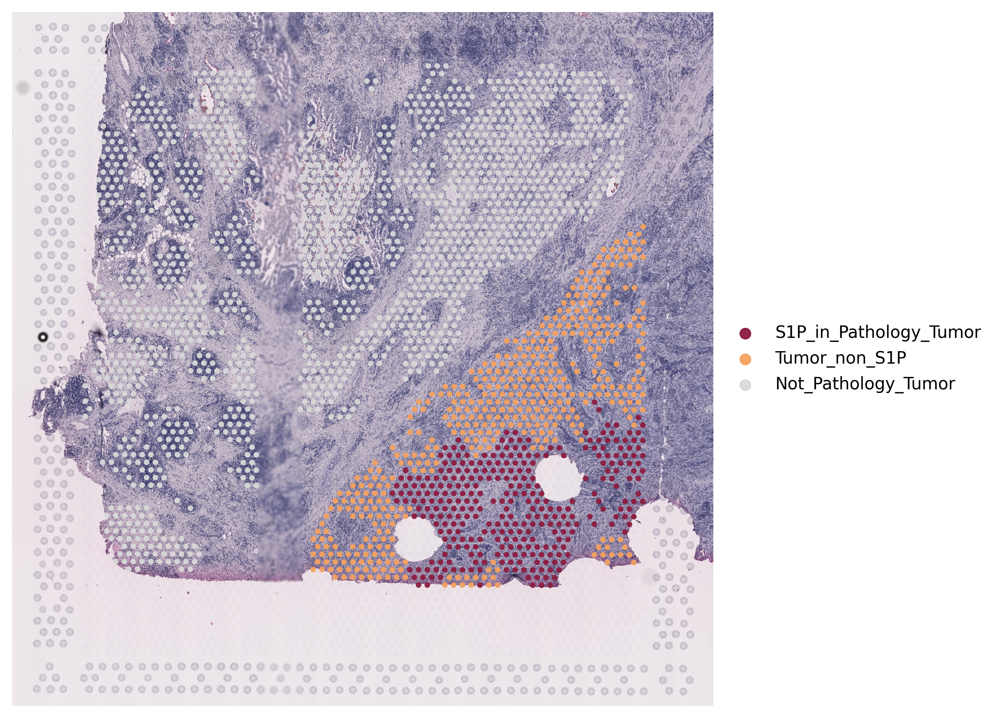

No-title figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/Figure10B_Tumor_internal_S1P_vs_nonS1P_comparison_group_no_title.png


In [7]:
# =========================================================
# Cell 5.1: 可选辅助图 - 病理肿瘤内部 S1P vs 非 S1P 区域（无标题版本）
# =========================================================

comparison_categories = [
    "S1P_in_Pathology_Tumor",
    "Tumor_non_S1P",
    "Not_Pathology_Tumor"
]

comparison_palette = {
    "S1P_in_Pathology_Tumor": "#8c1d40",
    "Tumor_non_S1P": "#f4a261",
    "Not_Pathology_Tumor": "#d9d9d9",
}

adata.obs["Tumor_Internal_S1P_Comparison"] = pd.Categorical(
    adata.obs["Tumor_Internal_S1P_Comparison"].astype(str),
    categories=comparison_categories,
    ordered=True,
)

adata.uns["Tumor_Internal_S1P_Comparison_colors"] = [
    comparison_palette[x] for x in comparison_categories
]

fig, ax = plt.subplots(1, 1, figsize=(8, 7), dpi=300)

sq.pl.spatial_scatter(
    adata,
    library_id=library_id,
    img=True,
    color="Tumor_Internal_S1P_Comparison",
    size=10,
    alpha=0.95,
    title="",              # 不显示标题
    frameon=False,
    legend_loc="right margin",
    ax=ax,
)

# 双保险：清空 Matplotlib 轴标题
ax.set_title("")

plt.tight_layout()

fig_path_no_title = os.path.join(
    FIG_DIR,
    "Figure10B_Tumor_internal_S1P_vs_nonS1P_comparison_group_no_title.png"
)

plt.savefig(
    fig_path_no_title,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1
)

plt.show()

print("No-title figure saved:", fig_path_no_title)

Available S1P genes: ['SPHK1', 'SPHK2', 'SPNS2', 'S1PR1', 'S1PR2', 'S1PR3']
Missing S1P genes: []
表达矩阵检查：max=63.0000, integer_like_ratio=1.0000
检测到表达矩阵类似 raw counts，将进行 normalize_total + log1p 后计算 score。
已计算 S1P_Axis_Gene_Score。


,feature,mean_S1P_in_Pathology_Tumor,mean_Tumor_non_S1P,median_S1P_in_Pathology_Tumor,median_Tumor_non_S1P,delta_mean,mannwhitney_pvalue,n_S1P,n_Tumor_non_S1P
0,S1P_Axis_Gene_Score,-0.021989,-0.0024,-0.022966,-0.102184,-0.019589,0.510157,312,460


Saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/tables/S1P_axis_score_TumorInternal_comparison_stats.csv


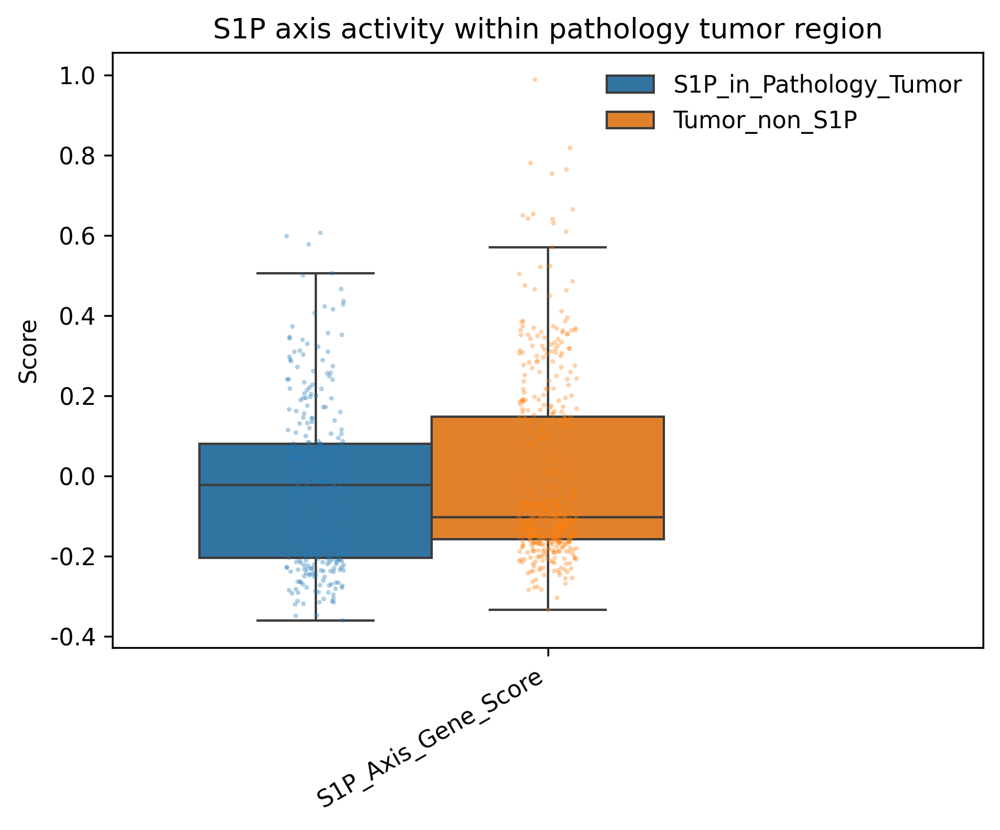

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/S1P_axis_score_TumorInternal_comparison.png


In [8]:
# =========================================================
# Cell 6: S1P 轴基因/score 验证
# 目的：
# 1) 检验病理肿瘤区域内部的 TMCN_S1P_Axis 是否具有 S1P 轴相关表达特征；
# 2) 比较 S1P_in_Pathology_Tumor vs Tumor_non_S1P；
# 3) 若最终 h5ad 中仍保留 Coupling_S1P 等列，则自动合并作为补充。
# =========================================================

import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

# ---------------------------------------------------------
# 1. 检查 S1P 轴基因
# ---------------------------------------------------------
available_s1p_genes = [g for g in S1P_AXIS_GENES if g in adata.var_names]
missing_s1p_genes = [g for g in S1P_AXIS_GENES if g not in adata.var_names]

print("Available S1P genes:", available_s1p_genes)
print("Missing S1P genes:", missing_s1p_genes)


# ---------------------------------------------------------
# 2. 稳健判断表达矩阵是否像 raw counts
# 修正点：
# - 不能简单用 hasattr(X, 'data')，因为 numpy dense array 也有 .data；
# - 只有 scipy sparse matrix 才用 X.data；
# - dense matrix 用 np.asarray(X)；
# - backed / view 情况下尽量转成真实数组；
# ---------------------------------------------------------
def looks_like_counts(adata_obj, n_check=10000, random_state=42):
    X = adata_obj.X

    if sp.issparse(X):
        vals = X.data
    else:
        vals = np.asarray(X)

        # 某些特殊对象可能转成 object array，这里强制展开
        if vals.dtype == object:
            vals = np.asarray(vals.tolist())

        vals = vals.ravel()

    vals = np.asarray(vals)
    vals = vals[np.isfinite(vals)]

    if vals.size == 0:
        return False

    # 只抽样一部分，避免矩阵过大
    if vals.size > n_check:
        rng = np.random.default_rng(random_state)
        vals = rng.choice(vals, size=n_check, replace=False)

    max_val = np.nanmax(vals)
    integer_like_ratio = np.mean(np.isclose(vals, np.round(vals)))

    print(f"表达矩阵检查：max={max_val:.4f}, integer_like_ratio={integer_like_ratio:.4f}")

    # raw counts 通常最大值较大，且绝大多数是整数
    return bool(max_val > 20 and integer_like_ratio > 0.95)


# ---------------------------------------------------------
# 3. 计算 S1P_Axis_Gene_Score
# ---------------------------------------------------------
adata_score = adata.copy()

if looks_like_counts(adata_score):
    print("检测到表达矩阵类似 raw counts，将进行 normalize_total + log1p 后计算 score。")
    sc.pp.normalize_total(adata_score, target_sum=1e4)
    sc.pp.log1p(adata_score)
else:
    print("表达矩阵不像 raw counts，将直接基于当前表达矩阵计算 score。")

if len(available_s1p_genes) >= 2:
    sc.tl.score_genes(
        adata_score,
        gene_list=available_s1p_genes,
        score_name="S1P_Axis_Gene_Score",
        ctrl_size=min(50, max(1, len(available_s1p_genes) * 5)),
        random_state=42,
        use_raw=False,
    )

    adata.obs["S1P_Axis_Gene_Score"] = adata_score.obs["S1P_Axis_Gene_Score"].values
    print("已计算 S1P_Axis_Gene_Score。")

else:
    adata.obs["S1P_Axis_Gene_Score"] = np.nan
    print("⚠️ 可用 S1P 轴基因少于 2 个，跳过 score_genes。")


# ---------------------------------------------------------
# 4. 如果最终 h5ad 中仍保留 Coupling_S1P 等列，则合并作为补充
# ---------------------------------------------------------
for possible_col in [
    "Coupling_S1P",
    "Active_S1P",
    "S1P_Sender_Score",
    "S1P_Receiver_Score"
]:
    if possible_col in adata_final_sub.obs.columns:
        adata.obs[possible_col] = pd.to_numeric(
            adata_final_sub.obs[possible_col],
            errors="coerce"
        ).values
        print(f"检测到并合并: {possible_col}")


# ---------------------------------------------------------
# 5. 统计检验：
# S1P_in_Pathology_Tumor vs Tumor_non_S1P
# ---------------------------------------------------------
score_cols = ["S1P_Axis_Gene_Score"] + [
    c for c in [
        "Coupling_S1P",
        "Active_S1P",
        "S1P_Sender_Score",
        "S1P_Receiver_Score"
    ]
    if c in adata.obs.columns
]

score_records = []

for col in score_cols:
    x = pd.to_numeric(
        adata.obs.loc[target_in_tumor_mask, col],
        errors="coerce"
    ).dropna()

    y = pd.to_numeric(
        adata.obs.loc[tumor_non_s1p_mask, col],
        errors="coerce"
    ).dropna()

    if len(x) >= 3 and len(y) >= 3:
        stat, p = mannwhitneyu(x, y, alternative="two-sided")

        score_records.append({
            "feature": col,
            "mean_S1P_in_Pathology_Tumor": float(x.mean()),
            "mean_Tumor_non_S1P": float(y.mean()),
            "median_S1P_in_Pathology_Tumor": float(x.median()),
            "median_Tumor_non_S1P": float(y.median()),
            "delta_mean": float(x.mean() - y.mean()),
            "mannwhitney_pvalue": float(p),
            "n_S1P": int(len(x)),
            "n_Tumor_non_S1P": int(len(y)),
        })

    else:
        print(f"⚠️ {col} 可用样本数不足，跳过统计检验。")
        print(f"   n_S1P={len(x)}, n_Tumor_non_S1P={len(y)}")

score_stats_df = pd.DataFrame(score_records)

score_stats_path = os.path.join(
    TABLE_DIR,
    "S1P_axis_score_TumorInternal_comparison_stats.csv"
)

score_stats_df.to_csv(
    score_stats_path,
    index=False,
    encoding="utf-8-sig"
)

display(score_stats_df)
print("Saved:", score_stats_path)


# ---------------------------------------------------------
# 6. 可视化 score
# ---------------------------------------------------------
plot_df = adata.obs.loc[
    pathology_tumor_mask,
    ["Result10_Group"] + score_cols
].copy()

plot_df = plot_df[
    plot_df["Result10_Group"].isin([
        "S1P_in_Pathology_Tumor",
        "Tumor_non_S1P"
    ])
]

plot_df_long = plot_df.melt(
    id_vars="Result10_Group",
    value_vars=score_cols,
    var_name="score",
    value_name="value"
)

plot_df_long["value"] = pd.to_numeric(
    plot_df_long["value"],
    errors="coerce"
)

plot_df_long = plot_df_long.dropna(subset=["value"])

if not plot_df_long.empty:
    plt.figure(figsize=(max(6, 3.2 * len(score_cols)), 5), dpi=300)

    sns.boxplot(
        data=plot_df_long,
        x="score",
        y="value",
        hue="Result10_Group",
        showfliers=False
    )

    sns.stripplot(
        data=plot_df_long,
        x="score",
        y="value",
        hue="Result10_Group",
        dodge=True,
        size=2,
        alpha=0.35
    )

    handles, labels = plt.gca().get_legend_handles_labels()

    # 去掉 boxplot 和 stripplot 造成的重复图例
    unique = []
    unique_labels = []
    for h, l in zip(handles, labels):
        if l not in unique_labels:
            unique.append(h)
            unique_labels.append(l)

    plt.legend(
        unique[:2],
        unique_labels[:2],
        frameon=False,
        loc="best"
    )

    plt.xticks(rotation=30, ha="right")
    plt.xlabel("")
    plt.ylabel("Score")
    plt.title("S1P axis activity within pathology tumor region")

    plt.tight_layout()

    fig_path = os.path.join(
        FIG_DIR,
        "S1P_axis_score_TumorInternal_comparison.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Figure saved:", fig_path)

else:
    print("⚠️ 没有可用于绘图的 S1P score 数据。")

,gene,mean_S1P_in_Pathology_Tumor,mean_Tumor_non_S1P,delta_mean,mannwhitney_pvalue
0,SPHK1,0.495701,0.261947,0.233754,3.123557e-12
1,SPHK2,0.177876,0.139681,0.038195,6.914864e-04
2,SPNS2,0.031682,0.057929,-0.026247,9.243025e-01
3,S1PR1,0.018759,0.051761,-0.033002,6.362959e-01
4,S1PR2,0.123835,0.068287,0.055549,2.190843e-04
5,S1PR3,0.604679,0.361049,0.243630,3.681434e-10


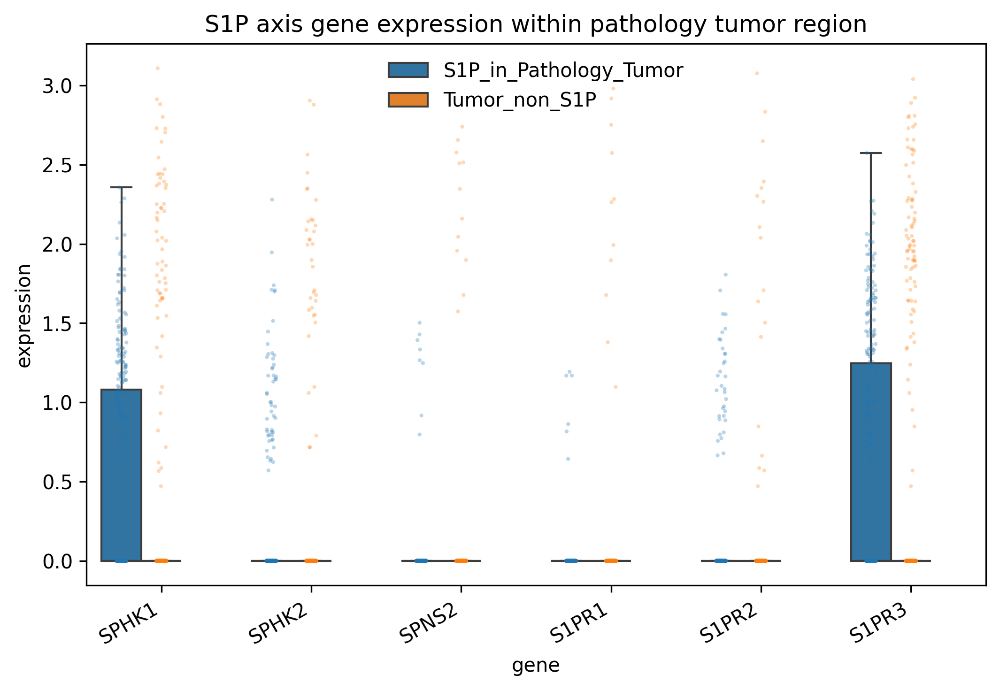

Saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/tables/S1P_axis_gene_expression_TumorInternal_comparison_stats.csv
Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/S1P_axis_gene_expression_TumorInternal_comparison.png


In [9]:
# =========================================================
# Cell 7: 单基因表达比较：SPHK1/SPHK2/SPNS2/S1PR1/S1PR2/S1PR3
# =========================================================
# 使用 adata_score 中的 normalized/log 表达进行可视化和统计
if len(available_s1p_genes) > 0:
    expr_df = sc.get.obs_df(adata_score, keys=available_s1p_genes)
    expr_df["Result10_Group"] = adata.obs["Result10_Group"].values
    expr_df = expr_df.loc[pathology_tumor_mask.values]
    expr_df = expr_df[expr_df["Result10_Group"].isin(["S1P_in_Pathology_Tumor", "Tumor_non_S1P"])]

    records = []
    for g in available_s1p_genes:
        x = pd.to_numeric(expr_df.loc[expr_df["Result10_Group"] == "S1P_in_Pathology_Tumor", g], errors="coerce").dropna()
        y = pd.to_numeric(expr_df.loc[expr_df["Result10_Group"] == "Tumor_non_S1P", g], errors="coerce").dropna()
        if len(x) >= 3 and len(y) >= 3:
            stat, p = mannwhitneyu(x, y, alternative="two-sided")
            records.append({
                "gene": g,
                "mean_S1P_in_Pathology_Tumor": float(x.mean()),
                "mean_Tumor_non_S1P": float(y.mean()),
                "delta_mean": float(x.mean() - y.mean()),
                "mannwhitney_pvalue": float(p),
            })
    gene_stats_df = pd.DataFrame(records)
    gene_stats_path = os.path.join(TABLE_DIR, "S1P_axis_gene_expression_TumorInternal_comparison_stats.csv")
    gene_stats_df.to_csv(gene_stats_path, index=False, encoding="utf-8-sig")
    display(gene_stats_df)

    expr_long = expr_df.melt(id_vars="Result10_Group", value_vars=available_s1p_genes, var_name="gene", value_name="expression")
    plt.figure(figsize=(max(7, 1.2 * len(available_s1p_genes)), 5), dpi=300)
    sns.boxplot(data=expr_long, x="gene", y="expression", hue="Result10_Group", showfliers=False)
    sns.stripplot(data=expr_long, x="gene", y="expression", hue="Result10_Group", dodge=True, size=2, alpha=0.30)
    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], frameon=False, loc="best")
    plt.xticks(rotation=30, ha="right")
    plt.title("S1P axis gene expression within pathology tumor region")
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "S1P_axis_gene_expression_TumorInternal_comparison.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", gene_stats_path)
    print("Figure saved:", fig_path)
else:
    print("没有可用 S1P 轴基因，跳过单基因表达比较。")

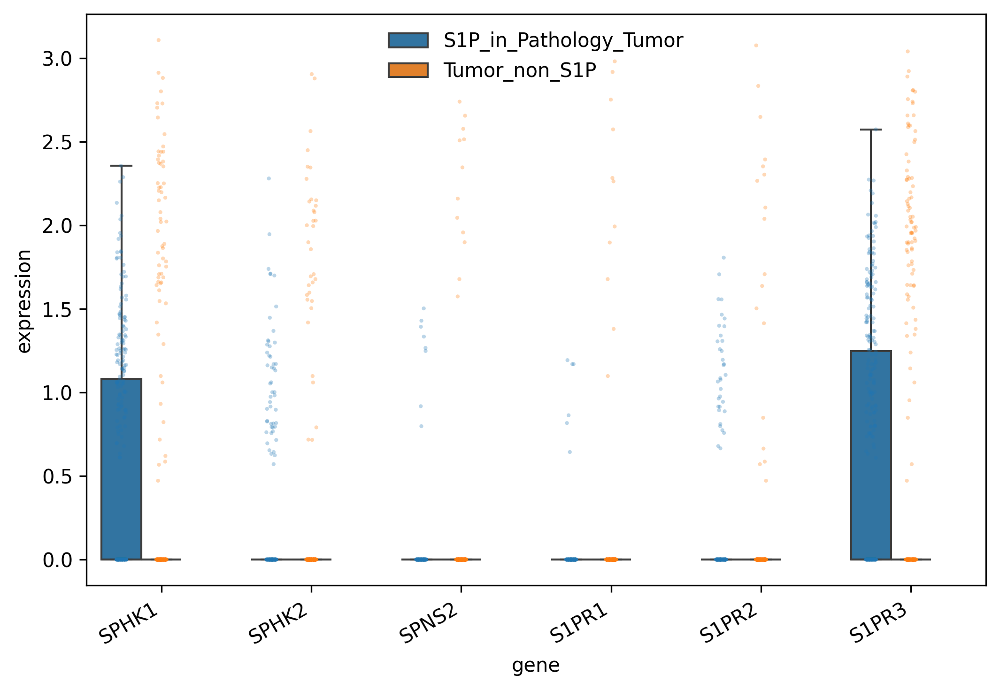

No-title figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/S1P_axis_gene_expression_TumorInternal_comparison_no_title.png


In [10]:
# =========================================================
# Cell 7.1: 单基因表达比较（无标题版本）
# =========================================================
# 使用 adata_score 中的 normalized/log 表达进行可视化和统计
if len(available_s1p_genes) > 0:
    expr_df = sc.get.obs_df(adata_score, keys=available_s1p_genes)
    expr_df["Result10_Group"] = adata.obs["Result10_Group"].values
    expr_df = expr_df.loc[pathology_tumor_mask.values]
    expr_df = expr_df[expr_df["Result10_Group"].isin(["S1P_in_Pathology_Tumor", "Tumor_non_S1P"])]

    expr_long = expr_df.melt(
        id_vars="Result10_Group",
        value_vars=available_s1p_genes,
        var_name="gene",
        value_name="expression"
    )

    plt.figure(figsize=(max(7, 1.2 * len(available_s1p_genes)), 5), dpi=300)

    sns.boxplot(
        data=expr_long,
        x="gene",
        y="expression",
        hue="Result10_Group",
        showfliers=False
    )

    sns.stripplot(
        data=expr_long,
        x="gene",
        y="expression",
        hue="Result10_Group",
        dodge=True,
        size=2,
        alpha=0.30
    )

    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], frameon=False, loc="best")

    plt.xticks(rotation=30, ha="right")
    plt.title("")   # 不显示标题

    # 双保险：清空当前轴标题
    ax = plt.gca()
    ax.set_title("")

    plt.tight_layout()

    fig_path_no_title = os.path.join(
        FIG_DIR,
        "S1P_axis_gene_expression_TumorInternal_comparison_no_title.png"
    )
    plt.savefig(fig_path_no_title, dpi=300, bbox_inches="tight")
    plt.show()

    print("No-title figure saved:", fig_path_no_title)
else:
    print("没有可用 S1P 轴基因，跳过单基因表达比较。")

AnnData object with n_obs × n_vars = 772 × 17845
    obs: 'in_tissue', 'x_array', 'y_array', 'x_pixel', 'y_pixel', 'manual_anno', 'manual_anno_tls', 'aestetik_manual_anno', 'aestetik_manual_anno_tls', 'ground_truth', 'blur_score', 'Ground_Truth_Binary', 'Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage M1', 'Macrophage M2', 'Macrophage other', 'Pathology_Binary_ARI', 'Level1_Macro_Region', 'Level2_Micro_Niche', 'Result10_Group', 'Highlight_TMCN_S1P_Axis', 'Tumor_Internal_S1P_Comparison', 'S1P_Axis_Gene_Score', 'DEG_Group'
    var: 'gene_ids', 'feature_types', 'gene_name'
    uns: 'Ground_Truth_Bin

表达矩阵检查：max=139.0000, integer_like_ratio=1.0000
DEG 矩阵类似 raw counts：执行 normalize_total + log1p。
过滤后用于 DEG 的基因数: 14504
DEG saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/DEG/DEG_S1P_in_Pathology_Tumor_vs_Tumor_non_S1P.csv


,gene,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,comparison,direction
0,UBC,13.597440,0.698630,4.146956e-42,3.007373e-38,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
1,FLNA,12.369875,1.251885,3.804121e-35,1.839166e-31,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
2,MT2A,11.226340,1.132638,3.027601e-29,1.097808e-25,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
3,PFN1,10.943664,1.076306,7.126099e-28,2.067139e-24,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
4,COL1A1,10.593729,0.845389,3.186389e-26,7.702565e-23,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
5,MMP14,10.429451,1.372798,1.819364e-25,3.298507e-22,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
6,NUCKS1,10.250866,2.067665,1.172877e-24,1.890156e-21,0.717949,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
7,ITGB1,10.191010,1.486572,2.174949e-24,2.867769e-21,0.980769,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
8,MYH9,10.191010,1.577525,2.174949e-24,2.867769e-21,0.977564,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P
9,LAMC2,10.105663,1.470200,5.214153e-24,6.302172e-21,1.000000,S1P_in_Pathology_Tumor_vs_Tumor_non_S1P,Up_in_S1P


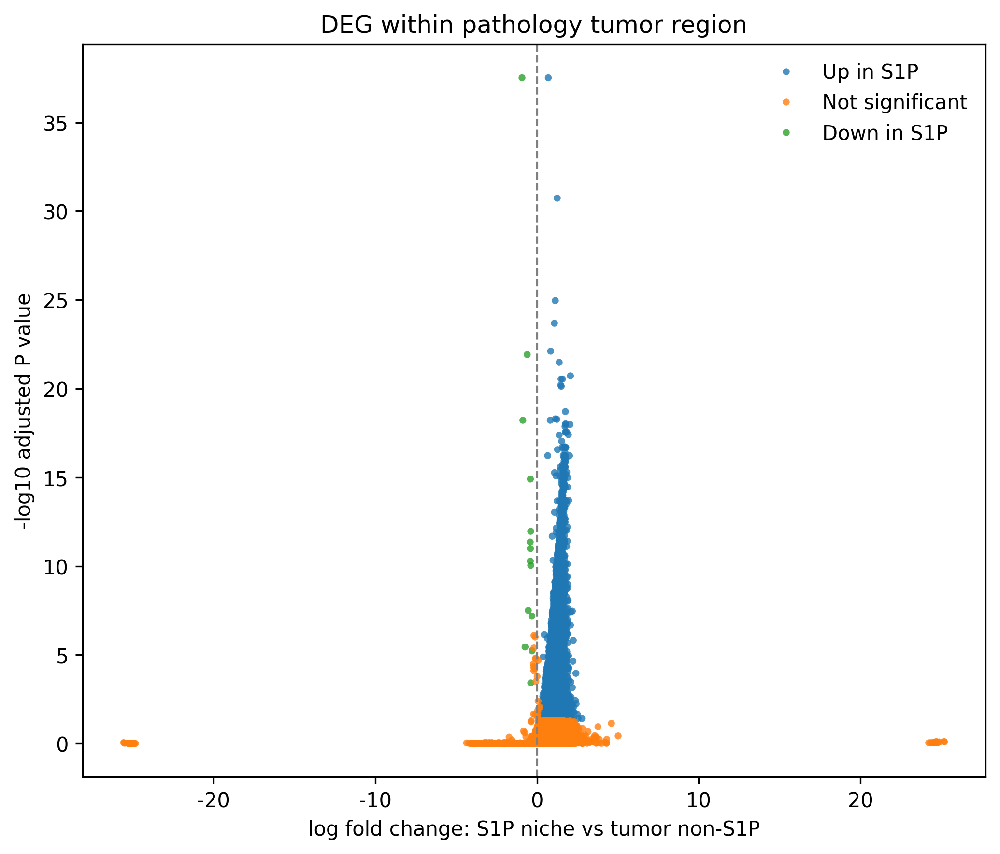

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/DEG_volcano_S1P_vs_Tumor_non_S1P.png


In [11]:
# =========================================================
# Cell 8: DEG - TMCN_S1P_Axis vs 病理肿瘤区域内非 S1P 区域
# =========================================================
# 注意：这里比较仅限 Pathology_Tumor 内部，避免把结论变成普通 Tumor vs Non-Tumor。
adata_deg = adata[pathology_tumor_mask].copy()
adata_deg.obs["DEG_Group"] = adata_deg.obs["Result10_Group"].astype(str)
adata_deg = adata_deg[adata_deg.obs["DEG_Group"].isin(["S1P_in_Pathology_Tumor", "Tumor_non_S1P"])].copy()
adata_deg.obs["DEG_Group"] = pd.Categorical(
    adata_deg.obs["DEG_Group"],
    categories=["S1P_in_Pathology_Tumor", "Tumor_non_S1P"],
    ordered=True,
)

print(adata_deg)
print(adata_deg.obs["DEG_Group"].value_counts())

# DEG 表达矩阵预处理：若像 raw counts，则 normalize + log1p；否则直接用当前矩阵
adata_deg_proc = adata_deg.copy()
if looks_like_counts(adata_deg_proc):
    print("DEG 矩阵类似 raw counts：执行 normalize_total + log1p。")
    sc.pp.normalize_total(adata_deg_proc, target_sum=1e4)
    sc.pp.log1p(adata_deg_proc)
else:
    print("DEG 矩阵不像 raw counts：直接使用当前表达矩阵。")

# 过滤极低表达基因，避免噪音
sc.pp.filter_genes(adata_deg_proc, min_cells=max(3, int(0.01 * adata_deg_proc.n_obs)))
print("过滤后用于 DEG 的基因数:", adata_deg_proc.n_vars)

sc.tl.rank_genes_groups(
    adata_deg_proc,
    groupby="DEG_Group",
    groups=["S1P_in_Pathology_Tumor"],
    reference="Tumor_non_S1P",
    method="wilcoxon",
    corr_method="benjamini-hochberg",
    pts=True,
)

deg_df = sc.get.rank_genes_groups_df(adata_deg_proc, group="S1P_in_Pathology_Tumor")
# 兼容 scanpy 输出字段
deg_df = deg_df.rename(columns={"names": "gene"})
if "gene" not in deg_df.columns:
    deg_df.insert(0, "gene", deg_df.index.astype(str))

deg_df["comparison"] = "S1P_in_Pathology_Tumor_vs_Tumor_non_S1P"
deg_df["direction"] = np.where(deg_df["logfoldchanges"] > 0, "Up_in_S1P", "Down_in_S1P")

deg_path = os.path.join(DEG_DIR, "DEG_S1P_in_Pathology_Tumor_vs_Tumor_non_S1P.csv")
deg_df.to_csv(deg_path, index=False, encoding="utf-8-sig")
print("DEG saved:", deg_path)
display(deg_df.head(20))

# 火山图
volcano_df = deg_df.copy()
volcano_df["neglog10_padj"] = -np.log10(volcano_df["pvals_adj"].replace(0, np.nextafter(0, 1)))
volcano_df["sig"] = "Not significant"
volcano_df.loc[(volcano_df["pvals_adj"] < 0.05) & (volcano_df["logfoldchanges"] > 0.25), "sig"] = "Up in S1P"
volcano_df.loc[(volcano_df["pvals_adj"] < 0.05) & (volcano_df["logfoldchanges"] < -0.25), "sig"] = "Down in S1P"

plt.figure(figsize=(7, 6), dpi=300)
sns.scatterplot(data=volcano_df, x="logfoldchanges", y="neglog10_padj", hue="sig", s=12, linewidth=0, alpha=0.8)
plt.axvline(0, linestyle="--", linewidth=1, color="grey")
plt.xlabel("log fold change: S1P niche vs tumor non-S1P")
plt.ylabel("-log10 adjusted P value")
plt.title("DEG within pathology tumor region")
plt.legend(frameon=False)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "DEG_volcano_S1P_vs_Tumor_non_S1P.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print("Figure saved:", fig_path)

In [12]:
# =========================================================
# Cell 9: 读取 GMT 文件并执行 ORA 富集分析
# =========================================================
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests


def safe_filename(x, max_len=150):
    x = str(x)
    x = re.sub(r"[\\/:*?\"<>|()\[\]{} ,]+", "_", x)
    x = re.sub(r"_+", "_", x).strip("_")
    return x[:max_len]


def read_gmt(gmt_path):
    gene_sets = {}
    with open(gmt_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) >= 3:
                name = parts[0]
                genes = sorted(set([g.strip() for g in parts[2:] if g.strip()]))
                if len(genes) > 0:
                    gene_sets[name] = genes
    return gene_sets


def find_gmt_files(gmt_dir):
    p = Path(gmt_dir)
    if not p.exists():
        return []
    preferred_patterns = [
        "h.all*.gmt",
        "c2.cp.reactome*.gmt",
        "c2.cp.kegg*.gmt",
        "c5.go.bp*.gmt",
        "c5.go*.gmt",
    ]
    files = []
    for pat in preferred_patterns:
        files.extend(sorted(p.glob(pat)))
    # 去重并限制数量，避免一次读入太多
    seen = set()
    unique_files = []
    for f in files:
        if str(f) not in seen:
            unique_files.append(f)
            seen.add(str(f))
    if len(unique_files) == 0:
        unique_files = sorted(p.glob("*.gmt"))[:8]
    return unique_files


def ora_enrichment(query_genes, background_genes, gene_sets, min_size=5, max_size=500):
    query = set([g for g in query_genes if g in background_genes])
    bg = set(background_genes)
    n_query = len(query)
    rows = []
    if n_query == 0:
        return pd.DataFrame()
    for term, genes in gene_sets.items():
        gs = set(genes) & bg
        if len(gs) < min_size or len(gs) > max_size:
            continue
        a = len(query & gs)
        b = n_query - a
        c = len(gs) - a
        d = len(bg) - n_query - c
        if a == 0:
            continue
        odds, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        rows.append({
            "term": term,
            "overlap": a,
            "query_size": n_query,
            "term_size": len(gs),
            "background_size": len(bg),
            "odds_ratio": odds,
            "pvalue": p,
            "overlap_genes": ";".join(sorted(query & gs)),
        })
    res = pd.DataFrame(rows)
    if not res.empty:
        res["padj"] = multipletests(res["pvalue"].values, method="fdr_bh")[1]
        res = res.sort_values(["padj", "pvalue", "odds_ratio"], ascending=[True, True, False])
    return res

# 准备 query genes
background_genes = set(adata_deg_proc.var_names.astype(str))
up_genes = deg_df[(deg_df["logfoldchanges"] > 0.25) & (deg_df["pvals_adj"] < 0.05)]["gene"].astype(str).tolist()
down_genes = deg_df[(deg_df["logfoldchanges"] < -0.25) & (deg_df["pvals_adj"] < 0.05)]["gene"].astype(str).tolist()

# 如果阈值过严导致没有基因，使用排名前 300 个正/负向基因作为探索性 ORA
if len(up_genes) < 10:
    up_genes = deg_df.sort_values("logfoldchanges", ascending=False).head(300)["gene"].astype(str).tolist()
    print("⚠️ padj<0.05 且 logFC>0.25 的上调基因少于 10 个，改用 logFC 排名前 300 个基因做探索性 ORA。")
if len(down_genes) < 10:
    down_genes = deg_df.sort_values("logfoldchanges", ascending=True).head(300)["gene"].astype(str).tolist()
    print("⚠️ padj<0.05 且 logFC<-0.25 的下调基因少于 10 个，改用 logFC 最低前 300 个基因做探索性 ORA。")

print(f"Up query genes: {len(up_genes)} | Down query genes: {len(down_genes)}")

gmt_files = find_gmt_files(GMT_DIR)
print("GMT files:")
for f in gmt_files:
    print(" -", f)

all_ora_results = []
for gmt_file in gmt_files:
    gene_sets = read_gmt(gmt_file)
    print(f"\n读取 {gmt_file.name}: {len(gene_sets)} gene sets")
    for direction, genes in [("Up_in_S1P", up_genes), ("Down_in_S1P", down_genes)]:
        res = ora_enrichment(genes, background_genes, gene_sets, min_size=5, max_size=500)
        if not res.empty:
            res.insert(0, "direction", direction)
            res.insert(0, "gmt_file", gmt_file.name)
            all_ora_results.append(res)

if len(all_ora_results) > 0:
    ora_df = pd.concat(all_ora_results, ignore_index=True)
    ora_path = os.path.join(ENRICH_DIR, "ORA_S1P_vs_Tumor_non_S1P_all_results.csv")
    ora_df.to_csv(ora_path, index=False, encoding="utf-8-sig")
    print("ORA saved:", ora_path)
    display(ora_df.head(20))
else:
    ora_df = pd.DataFrame()
    print("未获得 ORA 结果，请检查 GMT 文件和 DEG 基因名是否匹配。")

Up query genes: 4188 | Down query genes: 14
GMT files:
 - /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB/h.all.v2026.1.Hs.symbols.gmt
 - /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/GMT/MSigDB/c2.cp.reactome.v2026.1.Hs.symbols.gmt

读取 h.all.v2026.1.Hs.symbols.gmt: 50 gene sets

读取 c2.cp.reactome.v2026.1.Hs.symbols.gmt: 1839 gene sets


ORA saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/enrichment/ORA_S1P_vs_Tumor_non_S1P_all_results.csv


,gmt_file,direction,term,overlap,query_size,term_size,background_size,odds_ratio,pvalue,overlap_genes,padj
0,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_MYC_TARGETS_V1,118,4188,164,14504,6.472920,2.224100e-30,ACP1;APEX1;BUB3;CANX;CCT2;CCT3;CCT5;CCT7;CDC20...,1.112050e-28
1,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_OXIDATIVE_PHOSPHORYLATION,111,4188,164,14504,5.272065,5.119043e-25,ACAA1;ACADM;ACADVL;ACO2;ATP1B1;ATP5F1A;ATP5F1B...,1.279761e-23
2,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,115,4188,185,14504,4.132756,3.265471e-21,AREG;BGN;BMP1;CADM1;CALD1;CALU;CAPG;CCN1;CD44;...,5.442451e-20
3,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_MTORC1_SIGNALING,101,4188,171,14504,3.617204,1.379338e-16,ACACA;ACLY;ACSL3;ACTR3;AK4;ARPC5L;ATP2A2;ATP6V...,1.724172e-15
4,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_HYPOXIA,102,4188,177,14504,3.408654,1.003831e-15,ADM;AK4;ANKZF1;ANXA2;B3GALT6;BGN;BHLHE40;BNIP3...,1.003831e-14
5,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_TNFA_SIGNALING_VIA_NFKB,102,4188,186,14504,3.040766,8.413251e-14,AREG;B4GALT1;B4GALT5;BHLHE40;BIRC2;BMP2;BTG2;B...,7.011043e-13
6,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_P53_PATHWAY,95,4188,178,14504,2.861586,4.977338e-12,ABHD4;ACVR1B;AK1;APP;BAIAP2;BAX;BLCAP;BMP2;BTG...,3.555242e-11
7,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_APICAL_JUNCTION,93,4188,179,14504,2.701508,5.958794e-11,ACTB;ACTN1;ACTN4;ADAM15;AKT2;AKT3;ARPC2;B4GALT...,3.724246e-10
8,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_APOPTOSIS,77,4188,146,14504,2.781576,1.059498e-09,ADD1;ANKH;ANXA1;APP;BAX;BCAP31;BCL2L1;BCL2L2;B...,5.886102e-09
9,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_PROTEIN_SECRETION,50,4188,91,14504,3.028151,1.618165e-07,AP2B1;AP2M1;AP2S1;ARCN1;ARF1;ARFGAP3;ARFGEF2;A...,8.090824e-07


Medical-relevant ORA terms saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/enrichment/ORA_S1P_vs_Tumor_non_S1P_medical_relevant_terms.csv


,gmt_file,direction,term,overlap,query_size,term_size,background_size,odds_ratio,pvalue,overlap_genes,padj,term_upper
1718,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Down_in_S1P,REACTOME_ANTI_INFLAMMATORY_RESPONSE_FAVOURING_...,3,14,74,14504,55.386684,4.457144e-05,IGHG1;IGHG2;IGKV4-1,2.228572e-04,REACTOME_ANTI_INFLAMMATORY_RESPONSE_FAVOURING_...
1723,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Down_in_S1P,REACTOME_CELL_SURFACE_INTERACTIONS_AT_THE_VASC...,2,14,112,14504,21.787879,5.061763e-03,IGHA1;IGKV4-1,1.557465e-02,REACTOME_CELL_SURFACE_INTERACTIONS_AT_THE_VASC...
1733,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Down_in_S1P,REACTOME_FCERI_MEDIATED_MAPK_ACTIVATION,1,14,35,14504,32.705882,3.327364e-02,IGKV4-1,5.786719e-02,REACTOME_FCERI_MEDIATED_MAPK_ACTIVATION
1736,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Down_in_S1P,REACTOME_FCERI_MEDIATED_NF_KB_ACTIVATION,1,14,67,14504,16.811189,6.279270e-02,IGKV4-1,9.660416e-02,REACTOME_FCERI_MEDIATED_NF_KB_ACTIVATION
5,h.all.v2026.1.Hs.symbols.gmt,Up_in_S1P,HALLMARK_TNFA_SIGNALING_VIA_NFKB,102,4188,186,14504,3.040766,8.413251e-14,AREG;B4GALT1;B4GALT5;BHLHE40;BIRC2;BMP2;BTG2;B...,7.011043e-13,HALLMARK_TNFA_SIGNALING_VIA_NFKB
88,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Up_in_S1P,REACTOME_REGULATION_OF_T_CELL_ACTIVATION_BY_CD...,119,4188,225,14504,2.816950,2.429216e-14,ADRM1;AGO1;AGO2;AKT1;AKT2;AKT3;BRD4;CCND1;CDK4...,1.183171e-12,REACTOME_REGULATION_OF_T_CELL_ACTIVATION_BY_CD...
131,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Up_in_S1P,REACTOME_MAPK6_MAPK4_SIGNALING,46,4188,67,14504,5.444460,1.674314e-11,ADRM1;AGO1;AGO2;CDC42EP5;DNAJB1;FOXO1;FOXO3;HS...,3.600861e-10,REACTOME_MAPK6_MAPK4_SIGNALING
162,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Up_in_S1P,REACTOME_DECTIN_1_MEDIATED_NONCANONICAL_NF_KB_...,32,4188,43,14504,7.213230,8.005398e-10,ADRM1;FBXW11;NFKB2;PSMA1;PSMA2;PSMA3;PSMA4;PSM...,1.227494e-08,REACTOME_DECTIN_1_MEDIATED_NONCANONICAL_NF_KB_...
171,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Up_in_S1P,REACTOME_MAPK_FAMILY_SIGNALING_CASCADES,117,4188,254,14504,2.135351,3.608832e-09,ACTB;ADRM1;AGO1;AGO2;ARAF;AREG;ARL2;BCL2L1;CAM...,5.107885e-08,REACTOME_MAPK_FAMILY_SIGNALING_CASCADES
187,c2.cp.reactome.v2026.1.Hs.symbols.gmt,Up_in_S1P,REACTOME_FCERI_MEDIATED_NF_KB_ACTIVATION,41,4188,67,14504,3.912838,3.588976e-08,ADRM1;CDC34;FBXW11;IKBKB;IKBKG;LYN;MALT1;MAP3K...,4.468680e-07,REACTOME_FCERI_MEDIATED_NF_KB_ACTIVATION


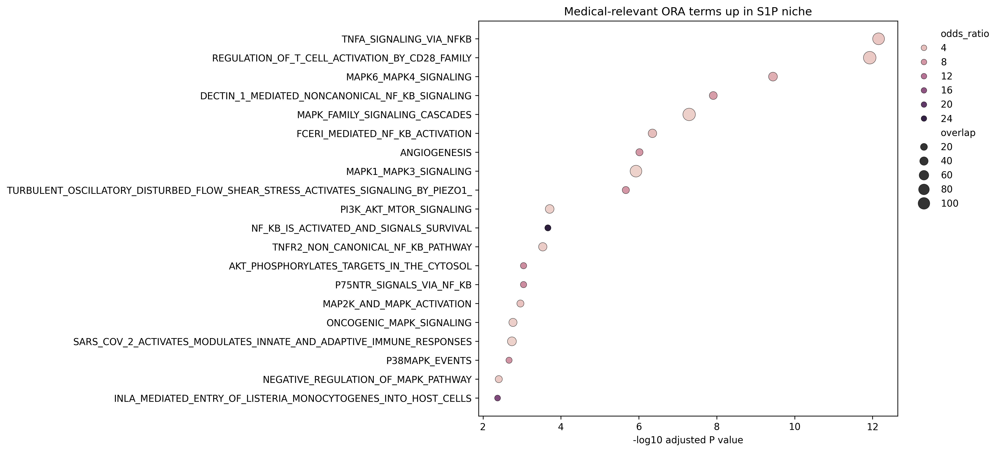

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/ORA_medical_relevant_terms_Up_in_S1P.png


In [13]:
# =========================================================
# Cell 10: 筛选与医学/临床现象相关的富集结果
# 注意：这里只是根据实际富集结果筛选，不预设结论。
# =========================================================
if not ora_df.empty:
    keyword_pattern = "|".join([re.escape(k) for k in FUNCTION_KEYWORDS])
    ora_df["term_upper"] = ora_df["term"].astype(str).str.upper()
    relevant_ora_df = ora_df[ora_df["term_upper"].str.contains(keyword_pattern, regex=True, na=False)].copy()
    relevant_ora_df = relevant_ora_df.sort_values(["direction", "padj", "pvalue", "odds_ratio"], ascending=[True, True, True, False])
    relevant_path = os.path.join(ENRICH_DIR, "ORA_S1P_vs_Tumor_non_S1P_medical_relevant_terms.csv")
    relevant_ora_df.drop(columns=["term_upper"], errors="ignore").to_csv(relevant_path, index=False, encoding="utf-8-sig")
    print("Medical-relevant ORA terms saved:", relevant_path)
    display(relevant_ora_df.head(30))

    # 可视化 Up_in_S1P 中最相关通路
    plot_ora = relevant_ora_df[relevant_ora_df["direction"] == "Up_in_S1P"].copy()
    plot_ora = plot_ora.sort_values("padj").head(20)
    if not plot_ora.empty:
        plot_ora["neglog10_padj"] = -np.log10(plot_ora["padj"].replace(0, np.nextafter(0, 1)))
        plot_ora["term_clean"] = plot_ora["term"].astype(str).str.replace("HALLMARK_", "", regex=False)
        plot_ora["term_clean"] = plot_ora["term_clean"].str.replace("REACTOME_", "", regex=False)
        plot_ora["term_clean"] = plot_ora["term_clean"].str.replace("GOBP_", "", regex=False)
        plot_ora["term_clean"] = plot_ora["term_clean"].str.slice(0, 80)

        plt.figure(figsize=(8, max(4, 0.38 * len(plot_ora))), dpi=300)
        sns.scatterplot(
            data=plot_ora,
            x="neglog10_padj",
            y="term_clean",
            size="overlap",
            hue="odds_ratio",
            sizes=(40, 180),
            edgecolor="black",
            linewidth=0.3,
        )
        plt.xlabel("-log10 adjusted P value")
        plt.ylabel("")
        plt.title("Medical-relevant ORA terms up in S1P niche")
        plt.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        fig_path = os.path.join(FIG_DIR, "ORA_medical_relevant_terms_Up_in_S1P.png")
        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.show()
        print("Figure saved:", fig_path)
    else:
        print("没有 Up_in_S1P 方向的医学相关富集条目。")
else:
    relevant_ora_df = pd.DataFrame()
    print("ORA 为空，跳过医学相关通路筛选。")

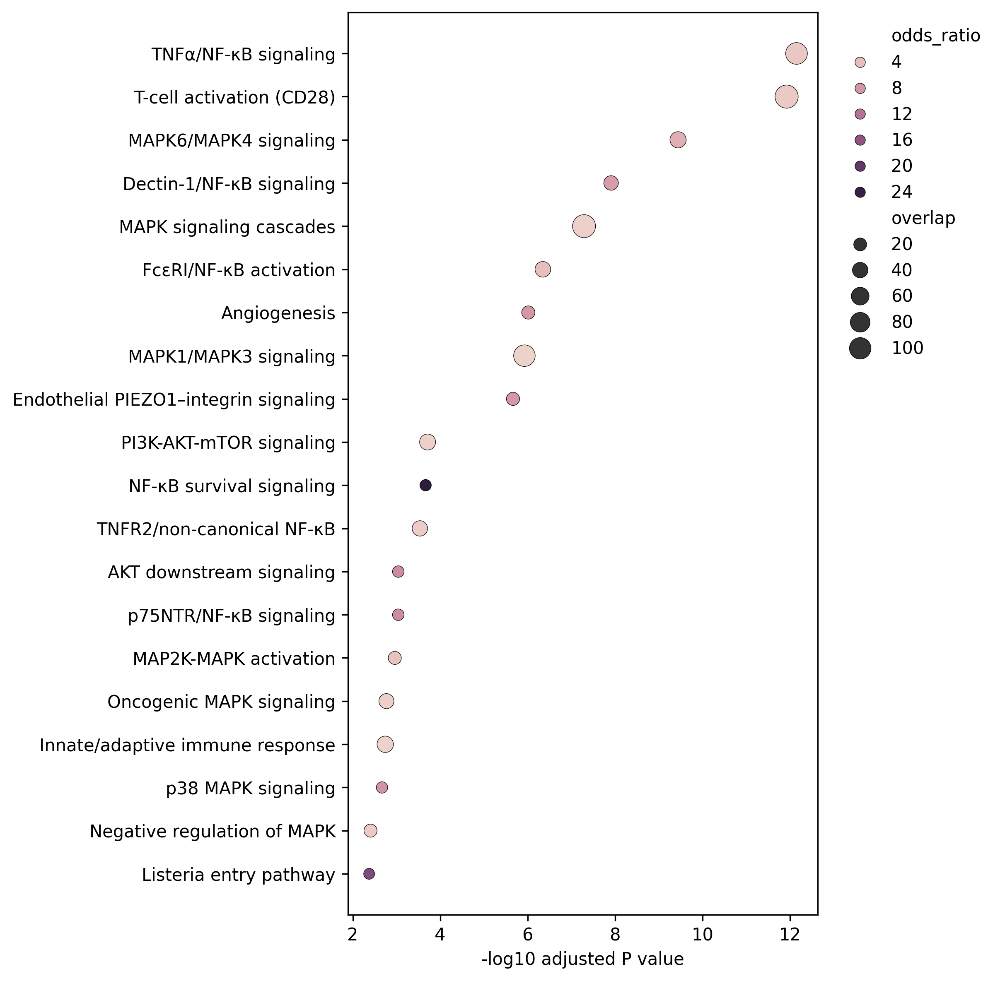

✅ 无标题 + 简洁通路名 ORA 图已保存： /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/ORA_medical_relevant_terms_Up_in_S1P_no_title_simple_labels.png


In [14]:
# =========================================================
# Cell 10.1: Medical-relevant ORA dotplot（无标题 + 简洁通路名版本）
# =========================================================

def simplify_medical_ora_term(term):
    """
    将 ORA term 转换为更适合论文展示的简洁形式
    """
    term = str(term)

    # 去掉常见数据库前缀
    for prefix in ["HALLMARK_", "REACTOME_", "GOBP_", "KEGG_", "WP_", "BIOCARTA_"]:
        if term.startswith(prefix):
            term = term.replace(prefix, "", 1)
      # 对超长机械力 / PIEZO1 / integrin 相关通路进行强制简化
    if (
        "PIEZO1" in term.upper()
        and "INTEGRIN" in term.upper()
        and "SHEAR_STRESS" in term.upper()
    ):
        return "Endothelial PIEZO1–integrin signaling"
    # 手动映射：优先处理这张图里常见/已出现的条目
    manual_map = {
        "TNFA_SIGNALING_VIA_NFKB": "TNFα/NF-κB signaling",
        "REGULATION_OF_T_CELL_ACTIVATION_BY_CD28_FAMILY": "T-cell activation (CD28)",
        "MAPK6_MAPK4_SIGNALING": "MAPK6/MAPK4 signaling",
        "DECTIN_1_MEDIATED_NONCANONICAL_NF_KB_SIGNALING": "Dectin-1/NF-κB signaling",
        "MAPK_FAMILY_SIGNALING_CASCADES": "MAPK signaling cascades",
        "FCERI_MEDIATED_NF_KB_ACTIVATION": "FcεRI/NF-κB activation",
        "ANGIOGENESIS": "Angiogenesis",
        "MAPK1_MAPK3_SIGNALING": "MAPK1/MAPK3 signaling",
        "TURBULENT_OSCILLATORY_DISTURBED_FLOW_SHEAR_STRESS_ACTIVATES_SIGNALING_BY_PIEZO1_": "PIEZO1-mediated mechanotransduction",
        "PI3K_AKT_MTOR_SIGNALING": "PI3K-AKT-mTOR signaling",
        "NF_KB_IS_ACTIVATED_AND_SIGNALS_SURVIVAL": "NF-κB survival signaling",
        "TNFR2_NON_CANONICAL_NF_KB_PATHWAY": "TNFR2/non-canonical NF-κB",
        "AKT_PHOSPHORYLATES_TARGETS_IN_THE_CYTOSOL": "AKT downstream signaling",
        "P75NTR_SIGNALS_VIA_NF_KB": "p75NTR/NF-κB signaling",
        "MAP2K_AND_MAPK_ACTIVATION": "MAP2K-MAPK activation",
        "ONCOGENIC_MAPK_SIGNALING": "Oncogenic MAPK signaling",
        "SARS_COV_2_ACTIVATES_MODULATES_INNATE_AND_ADAPTIVE_IMMUNE_RESPONSES": "Innate/adaptive immune response",
        "P38MAPK_EVENTS": "p38 MAPK signaling",
        "NEGATIVE_REGULATION_OF_MAPK_PATHWAY": "Negative regulation of MAPK",
        "INLA_MEDIATED_ENTRY_OF_LISTERIA_MONOCYTOGENES_INTO_HOST_CELLS": "Listeria entry pathway",
        "TGFβ_RECEPTOR_SIGNALING_IN_EMT_EPITHELIAL_TO_MESENCHYMAL_TRANSITION": "TGFβ signaling in EMT",
        "TGFB_RECEPTOR_SIGNALING_IN_EMT_EPITHELIAL_TO_MESENCHYMAL_TRANSITION": "TGFβ signaling in EMT",
    }

    if term in manual_map:
        return manual_map[term]

    # 通用清洗
    clean = term.replace("_", " ")

    # 常见缩写规范化
    replace_map = {
        "NFKB": "NF-κB",
        "NF KB": "NF-κB",
        "TNFA": "TNFα",
        "TGFB": "TGFβ",
        "MTOR": "mTOR",
        "PI3K": "PI3K",
        "AKT": "AKT",
        "MAPK": "MAPK",
        "EMT": "EMT",
        "CD28": "CD28",
        "FCERI": "FcεRI",
    }
    for old, new in replace_map.items():
        clean = clean.replace(old, new)

    # 首字母大写（尽量保持自然语言）
    clean = clean.lower()
    words = clean.split()
    clean = " ".join([w.capitalize() if w not in ["and", "of", "in", "by", "via"] else w for w in words])

    # 再次修正常见术语大小写
    clean = (
        clean.replace("Nf-κb", "NF-κB")
             .replace("Tnfα", "TNFα")
             .replace("Mtor", "mTOR")
             .replace("Pi3k", "PI3K")
             .replace("Akt", "AKT")
             .replace("Mapk", "MAPK")
             .replace("Emt", "EMT")
             .replace("Tgfβ", "TGFβ")
             .replace("Fcεri", "FcεRI")
    )

    return clean


if "relevant_ora_df" not in globals() or relevant_ora_df.empty:
    print("⚠️ relevant_ora_df 不存在或为空，请先运行 Cell 10。")
else:
    plot_ora_simple = relevant_ora_df[relevant_ora_df["direction"] == "Up_in_S1P"].copy()
    plot_ora_simple = plot_ora_simple.sort_values("padj").head(20)

    if plot_ora_simple.empty:
        print("⚠️ 没有 Up_in_S1P 方向的医学相关富集条目。")
    else:
        plot_ora_simple["neglog10_padj"] = -np.log10(
            plot_ora_simple["padj"].replace(0, np.nextafter(0, 1))
        )

        # 简洁标签
        plot_ora_simple["term_simple"] = plot_ora_simple["term"].apply(simplify_medical_ora_term)

        # 如果有重复简洁名，只保留 padj 更显著的一条
        plot_ora_simple = (
            plot_ora_simple
            .sort_values(["term_simple", "padj", "pvalue", "odds_ratio"],
                         ascending=[True, True, True, False])
            .drop_duplicates(subset=["term_simple"], keep="first")
            .copy()
        )

        # 重新取 Top 20
        plot_ora_simple = plot_ora_simple.sort_values("padj").head(20).copy()

        plt.figure(figsize=(8.2, max(4.2, 0.40 * len(plot_ora_simple))), dpi=300)

        sns.scatterplot(
            data=plot_ora_simple,
            x="neglog10_padj",
            y="term_simple",
            size="overlap",
            hue="odds_ratio",
            sizes=(40, 180),
            edgecolor="black",
            linewidth=0.3,
        )

        plt.xlabel("-log10 adjusted P value")
        plt.ylabel("")
        plt.title("")   # 不显示标题
        plt.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()

        fig_path_simple = os.path.join(
            FIG_DIR,
            "ORA_medical_relevant_terms_Up_in_S1P_no_title_simple_labels.png"
        )
        plt.savefig(fig_path_simple, dpi=300, bbox_inches="tight")
        plt.show()

        print("✅ 无标题 + 简洁通路名 ORA 图已保存：", fig_path_simple)

In [15]:
# =========================================================
# Cell 11: 可选 GSEA prerank 分析
# 如果服务器未安装 gseapy，本 Cell 会自动跳过，不影响 ORA 结果。
# =========================================================
try:
    import gseapy as gp
    print("gseapy 已安装，开始 prerank GSEA...")

    # 使用 signed score 排名：logFC * -log10(p)
    prerank_df = deg_df[["gene", "logfoldchanges", "pvals"]].copy()
    prerank_df["pvals"] = prerank_df["pvals"].replace(0, np.nextafter(0, 1))
    prerank_df["rank_score"] = prerank_df["logfoldchanges"] * (-np.log10(prerank_df["pvals"]))
    prerank_df = prerank_df.replace([np.inf, -np.inf], np.nan).dropna(subset=["gene", "rank_score"])
    prerank_df = prerank_df.sort_values("rank_score", ascending=False)
    prerank_rnk_path = os.path.join(ENRICH_DIR, "GSEA_prerank_input_S1P_vs_Tumor_non_S1P.rnk")
    prerank_df[["gene", "rank_score"]].to_csv(prerank_rnk_path, sep="\t", index=False, header=False)

    gsea_outputs = []
    for gmt_file in gmt_files:
        outdir = os.path.join(ENRICH_DIR, "gseapy_prerank", safe_filename(gmt_file.stem))
        os.makedirs(outdir, exist_ok=True)
        pre_res = gp.prerank(
            rnk=prerank_df[["gene", "rank_score"]],
            gene_sets=str(gmt_file),
            outdir=outdir,
            min_size=5,
            max_size=500,
            permutation_num=1000,
            seed=42,
            verbose=False,
        )
        res2d = pre_res.res2d.copy()
        res2d.insert(0, "gmt_file", gmt_file.name)
        gsea_outputs.append(res2d)

    if len(gsea_outputs) > 0:
        gsea_df = pd.concat(gsea_outputs, ignore_index=True)
        gsea_path = os.path.join(ENRICH_DIR, "GSEA_prerank_S1P_vs_Tumor_non_S1P_all_results.csv")
        gsea_df.to_csv(gsea_path, index=False, encoding="utf-8-sig")
        print("GSEA saved:", gsea_path)
        display(gsea_df.head(20))
    else:
        gsea_df = pd.DataFrame()
except Exception as e:
    gsea_df = pd.DataFrame()
    print("⚠️ GSEA prerank 跳过。原因：", repr(e))
    print("ORA 结果仍然可用于 Result 10 的主要功能富集分析。")

gseapy 已安装，开始 prerank GSEA...
GSEA saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/enrichment/GSEA_prerank_S1P_vs_Tumor_non_S1P_all_results.csv


,gmt_file,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,0.799705,1.272296,0.0,0.019004,0.019,88/185,10.64%,FLNA;TGFBI;GJA1;ITGB1;LAMC2;MMP14;TGFB1;FBLN2;...
1,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_ANGIOGENESIS,0.819336,1.250233,0.007007,0.014503,0.029,17/29,11.80%,PDGFA;POSTN;ITGAV;VEGFA;FSTL1;APP;JAG2;TNFRSF2...
2,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_APICAL_JUNCTION,0.770922,1.224734,0.0,0.026672,0.077,67/179,14.02%,TGFBI;MYH9;ACTN1;ITGB1;LAMC2;LAMB3;CDH3;PFN1;L...
3,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_HEDGEHOG_SIGNALING,0.7847,1.206983,0.013,0.033757,0.127,12/32,14.71%,MYH9;VEGFA;ETS2;ADGRG1;DPYSL2;PML;THY1;NRP2;VL...
4,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_APICAL_SURFACE,0.785987,1.205751,0.013026,0.027806,0.131,9/34,7.22%,SULF2;APP;FLOT2;EPHB4;AFAP1L2;PLAUR;B4GALT1;TH...
5,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_HYPOXIA,0.756696,1.20327,0.0,0.025005,0.141,77/177,15.76%,TGFBI;MYH9;PGK1;SLC2A1;MT2A;COL5A1;SDC4;ETS1;P...
6,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_MYC_TARGETS_V1,0.754372,1.200149,0.0,0.022719,0.149,94/164,17.93%,PGK1;HNRNPA2B1;HNRNPA3;EIF4G2;NME1;XRCC6;SET;C...
7,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_COAGULATION,0.756905,1.197473,0.0,0.021754,0.16,46/115,17.10%,WDR1;MMP14;HTRA1;TIMP3;RAC1;SPARC;C1S;CAPN2;AR...
8,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_ANDROGEN_RESPONSE,0.759333,1.189694,0.0,0.024338,0.197,33/92,13.69%,ACTN1;PMEPA1;SAT1;ITGAV;XRCC6;TMEM50A;SCD;AKT1...
9,h.all.v2026.1.Hs.symbols.gmt,prerank,HALLMARK_CHOLESTEROL_HOMEOSTASIS,0.741904,1.163651,0.013,0.040108,0.334,26/66,15.65%,ANXA5;S100A11;SCD;CTNNB1;MVD;PLAUR;ERRFI1;PMVK...


用于细胞组成分析的列:
['Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'Macrophage M1', 'Macrophage M2', 'in_tissue', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage other']


,cell_type,mean_S1P_in_Pathology_Tumor,mean_Tumor_non_S1P,median_S1P_in_Pathology_Tumor,median_Tumor_non_S1P,delta_mean,mannwhitney_pvalue,padj
0,Malignant,0.881848,0.465914,9.172142e-01,0.467148,0.415934,3.066871e-99,1.104074e-97
1,CAF,0.080777,0.344894,2.374036e-02,0.349807,-0.264116,5.909015e-86,1.063623e-84
9,pDC,0.003462,0.018873,7.459993e-07,0.006264,-0.015411,6.797553e-41,8.157063e-40
2,Endothelial,0.004527,0.022205,3.483542e-06,0.008123,-0.017678,3.258728e-40,2.932855e-39
5,T CD4,0.001026,0.017019,9.338802e-07,0.000205,-0.015993,2.240905e-39,1.613451e-38
4,B cell,0.001975,0.021237,1.687595e-06,0.002168,-0.019262,1.033094e-38,6.198567e-38
3,Plasma,0.005442,0.022281,2.474460e-06,0.011588,-0.016839,4.009028e-37,2.061786e-36
13,Unidentifiable,0.008558,0.038684,1.000000e-05,0.005932,-0.030126,2.437739e-33,1.096983e-32
12,Neutrophil,0.001450,0.007611,6.158723e-07,0.000595,-0.006161,1.690358e-32,6.761433e-32
22,Tfh,0.000259,0.005817,0.000000e+00,0.000027,-0.005558,6.792998e-29,2.445479e-28


Saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/tables/SpaCET_cell_fraction_S1P_vs_Tumor_non_S1P_stats.csv


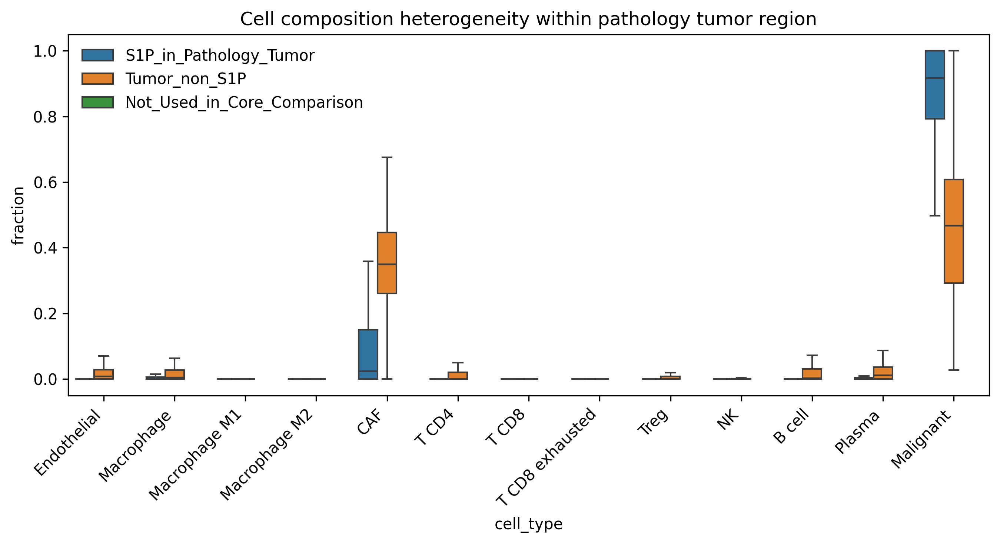

Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/SpaCET_cell_fraction_S1P_vs_Tumor_non_S1P.png


In [16]:
# =========================================================
# Cell 12: SpaCET 细胞组成异质性分析
# 目的：判断 S1P 生态位是否对应不同的肿瘤微环境组成，例如 Endothelial / immune / macrophage / CAF 等。
# =========================================================
known_cell_types = [
    "Malignant", "CAF", "Endothelial", "Plasma", "B cell", "T CD4", "T CD8", "NK",
    "cDC", "pDC", "Macrophage", "Mast", "Neutrophil", "Unidentifiable",
    "B cell naive", "B cell non-switched memory", "B cell switched memory", "B cell exhausted",
    "T CD4 naive", "Th1", "Th2", "Th17", "Tfh", "Treg",
    "T CD8 naive", "T CD8 central memory", "T CD8 effector memory", "T CD8 effector", "T CD8 exhausted",
    "Macrophage M1", "Macrophage M2",
]
cell_cols = [c for c in known_cell_types if c in adata.obs.columns]
# 再补充所有数值型、疑似 cell fraction 的列，但避免把 score/坐标/标签等加入
for c in adata.obs.columns:
    if c in cell_cols:
        continue
    if any(k in c for k in ["Score", "Coupling", "Active", "spatial", "array", "pixel", "Pathology", "Niche", "Region", "Group"]):
        continue
    vals = pd.to_numeric(adata.obs[c], errors="coerce")
    if vals.notna().mean() > 0.9 and vals.min() >= 0 and vals.max() <= 1.5:
        # 这类列很可能是细胞比例
        if c not in cell_cols:
            cell_cols.append(c)

print("用于细胞组成分析的列:")
print(cell_cols)

cell_records = []
for c in cell_cols:
    x = pd.to_numeric(adata.obs.loc[target_in_tumor_mask, c], errors="coerce").dropna()
    y = pd.to_numeric(adata.obs.loc[tumor_non_s1p_mask, c], errors="coerce").dropna()
    if len(x) >= 3 and len(y) >= 3:
        stat, p = mannwhitneyu(x, y, alternative="two-sided")
        cell_records.append({
            "cell_type": c,
            "mean_S1P_in_Pathology_Tumor": float(x.mean()),
            "mean_Tumor_non_S1P": float(y.mean()),
            "median_S1P_in_Pathology_Tumor": float(x.median()),
            "median_Tumor_non_S1P": float(y.median()),
            "delta_mean": float(x.mean() - y.mean()),
            "mannwhitney_pvalue": float(p),
        })

cell_stats_df = pd.DataFrame(cell_records)
if not cell_stats_df.empty:
    cell_stats_df["padj"] = multipletests(cell_stats_df["mannwhitney_pvalue"], method="fdr_bh")[1]
    cell_stats_df = cell_stats_df.sort_values(["padj", "mannwhitney_pvalue", "delta_mean"], ascending=[True, True, False])

cell_stats_path = os.path.join(TABLE_DIR, "SpaCET_cell_fraction_S1P_vs_Tumor_non_S1P_stats.csv")
cell_stats_df.to_csv(cell_stats_path, index=False, encoding="utf-8-sig")
display(cell_stats_df.head(30))
print("Saved:", cell_stats_path)

# 可视化：选择最重要的细胞类型 + 与 S1P 解释最相关的细胞类型
priority_cells = ["Endothelial", "Macrophage", "Macrophage M1", "Macrophage M2", "CAF", "T CD4", "T CD8", "T CD8 exhausted", "Treg", "NK", "B cell", "Plasma", "Malignant"]
plot_cells = [c for c in priority_cells if c in cell_cols]
if len(plot_cells) == 0 and not cell_stats_df.empty:
    plot_cells = cell_stats_df.head(12)["cell_type"].tolist()

if len(plot_cells) > 0:
    plot_df = adata.obs.loc[pathology_tumor_mask, ["Result10_Group"] + plot_cells].copy()
    plot_df = plot_df[plot_df["Result10_Group"].isin(["S1P_in_Pathology_Tumor", "Tumor_non_S1P"])]
    plot_long = plot_df.melt(id_vars="Result10_Group", value_vars=plot_cells, var_name="cell_type", value_name="fraction")
    plot_long["fraction"] = pd.to_numeric(plot_long["fraction"], errors="coerce")
    plot_long = plot_long.dropna(subset=["fraction"])

    plt.figure(figsize=(max(8, 0.7 * len(plot_cells)), 5), dpi=300)
    sns.boxplot(data=plot_long, x="cell_type", y="fraction", hue="Result10_Group", showfliers=False)
    plt.xticks(rotation=45, ha="right")
    plt.title("Cell composition heterogeneity within pathology tumor region")
    plt.legend(frameon=False, loc="best")
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "SpaCET_cell_fraction_S1P_vs_Tumor_non_S1P.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Figure saved:", fig_path)

,analysis,k,observed_same_fraction,permutation_mean,permutation_std,empirical_pvalue_greater,n_perm
0,Tumor_internal_S1P_spatial_clustering_knn_same...,8,0.913462,0.403573,0.011177,0.000999,1000


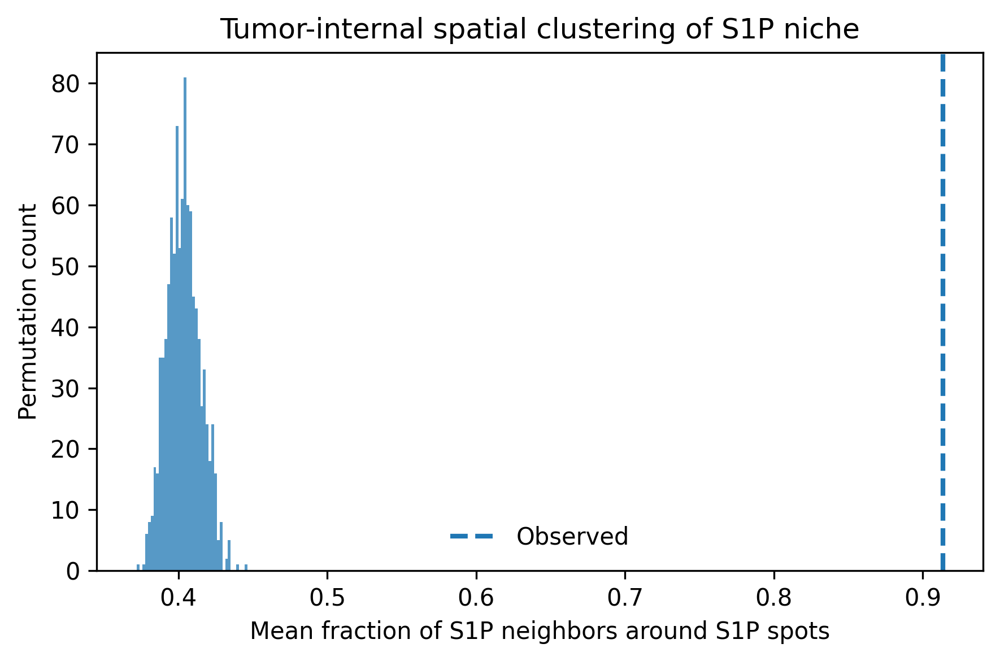

Saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/tables/S1P_tumor_internal_spatial_clustering_permutation.csv
Figure saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/figures/S1P_tumor_internal_spatial_clustering_permutation.png


In [17]:
# =========================================================
# Cell 13: 空间聚集性辅助分析
# 目的：检验 S1P 生态位在病理肿瘤区域内部是否形成空间局部聚集。
# 这不是临床结论的核心证据，但可支持该生态位不是随机散点。
# =========================================================
from scipy.spatial import cKDTree

coords = np.asarray(adata.obsm["spatial"])
coords_tumor = coords[pathology_tumor_mask.values]
labels_tumor = np.where(target_in_tumor_mask[pathology_tumor_mask].values, 1, 0)

# 在病理肿瘤区域内部构建 kNN，计算 S1P spot 的同类邻居比例
k = 8
if coords_tumor.shape[0] > k + 1 and labels_tumor.sum() > 0:
    tree = cKDTree(coords_tumor)
    dists, idxs = tree.query(coords_tumor, k=k+1)
    neigh = idxs[:, 1:]
    same_s1p_frac = []
    for i in range(coords_tumor.shape[0]):
        if labels_tumor[i] == 1:
            same_s1p_frac.append(labels_tumor[neigh[i]].mean())
    observed_same_frac = float(np.mean(same_s1p_frac)) if len(same_s1p_frac) > 0 else np.nan

    # permutation：固定 S1P 数量，打乱肿瘤内部标签
    rng = np.random.default_rng(42)
    n_perm = 1000
    perm_vals = []
    for _ in range(n_perm):
        perm_lab = labels_tumor.copy()
        rng.shuffle(perm_lab)
        vals = []
        for i in range(coords_tumor.shape[0]):
            if perm_lab[i] == 1:
                vals.append(perm_lab[neigh[i]].mean())
        perm_vals.append(float(np.mean(vals)) if len(vals) > 0 else np.nan)
    perm_vals = np.asarray(perm_vals)
    p_empirical = float((np.sum(perm_vals >= observed_same_frac) + 1) / (np.sum(np.isfinite(perm_vals)) + 1))

    spatial_summary = pd.DataFrame([{
        "analysis": "Tumor_internal_S1P_spatial_clustering_knn_same_fraction",
        "k": k,
        "observed_same_fraction": observed_same_frac,
        "permutation_mean": float(np.nanmean(perm_vals)),
        "permutation_std": float(np.nanstd(perm_vals)),
        "empirical_pvalue_greater": p_empirical,
        "n_perm": n_perm,
    }])
    spatial_path = os.path.join(TABLE_DIR, "S1P_tumor_internal_spatial_clustering_permutation.csv")
    spatial_summary.to_csv(spatial_path, index=False, encoding="utf-8-sig")
    display(spatial_summary)

    plt.figure(figsize=(6, 4), dpi=300)
    plt.hist(perm_vals[np.isfinite(perm_vals)], bins=40, alpha=0.75)
    plt.axvline(observed_same_frac, linestyle="--", linewidth=2, label="Observed")
    plt.xlabel("Mean fraction of S1P neighbors around S1P spots")
    plt.ylabel("Permutation count")
    plt.title("Tumor-internal spatial clustering of S1P niche")
    plt.legend(frameon=False)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "S1P_tumor_internal_spatial_clustering_permutation.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", spatial_path)
    print("Figure saved:", fig_path)
else:
    print("肿瘤区域 spots 或 S1P spots 数量不足，跳过空间聚集性 permutation。")

In [18]:
# =========================================================
# Cell 14: 自动生成 Result 10 汇总表与解释线索
# 说明：这里只根据实际统计结果生成提示，不提前写死结论。
# =========================================================
summary = {}
summary["sample"] = SAMPLE_NAME
summary["target_niche"] = TARGET_NICHE
summary["total_spots"] = int(adata.n_obs)
summary["pathology_tumor_spots"] = int(pathology_tumor_mask.sum())
summary["target_niche_all_spots"] = int(target_mask_all.sum())
summary["target_niche_in_pathology_tumor_spots"] = int(target_in_tumor_mask.sum())
summary["tumor_non_s1p_spots"] = int(tumor_non_s1p_mask.sum())
summary["target_niche_tumor_overlap_fraction"] = float(target_in_tumor_mask.sum() / max(target_mask_all.sum(), 1))

# S1P score summary
if "S1P_Axis_Gene_Score" in adata.obs.columns:
    x = pd.to_numeric(adata.obs.loc[target_in_tumor_mask, "S1P_Axis_Gene_Score"], errors="coerce").dropna()
    y = pd.to_numeric(adata.obs.loc[tumor_non_s1p_mask, "S1P_Axis_Gene_Score"], errors="coerce").dropna()
    summary["mean_S1P_Axis_Gene_Score_target"] = float(x.mean()) if len(x) else np.nan
    summary["mean_S1P_Axis_Gene_Score_tumor_non_s1p"] = float(y.mean()) if len(y) else np.nan
    summary["delta_mean_S1P_Axis_Gene_Score"] = summary["mean_S1P_Axis_Gene_Score_target"] - summary["mean_S1P_Axis_Gene_Score_tumor_non_s1p"]

# DEG summary
summary["n_DEG_up_in_S1P_padj005_logfc025"] = int(((deg_df["pvals_adj"] < 0.05) & (deg_df["logfoldchanges"] > 0.25)).sum())
summary["n_DEG_down_in_S1P_padj005_logfc025"] = int(((deg_df["pvals_adj"] < 0.05) & (deg_df["logfoldchanges"] < -0.25)).sum())
summary["top_up_genes"] = ";".join(deg_df.sort_values("logfoldchanges", ascending=False).head(20)["gene"].astype(str).tolist())
summary["top_down_genes"] = ";".join(deg_df.sort_values("logfoldchanges", ascending=True).head(20)["gene"].astype(str).tolist())

# relevant pathway summary
if 'relevant_ora_df' in globals() and not relevant_ora_df.empty:
    rel_up = relevant_ora_df[relevant_ora_df["direction"] == "Up_in_S1P"].sort_values("padj").head(20)
    summary["top_medical_relevant_terms_up_in_S1P"] = " | ".join(rel_up["term"].astype(str).tolist())
else:
    summary["top_medical_relevant_terms_up_in_S1P"] = ""

# cell composition summary
if 'cell_stats_df' in globals() and not cell_stats_df.empty:
    top_cell_up = cell_stats_df.sort_values("delta_mean", ascending=False).head(10)
    top_cell_down = cell_stats_df.sort_values("delta_mean", ascending=True).head(10)
    summary["cell_types_higher_in_S1P"] = " | ".join([f"{r.cell_type}({r.delta_mean:.4f})" for r in top_cell_up.itertuples()])
    summary["cell_types_lower_in_S1P"] = " | ".join([f"{r.cell_type}({r.delta_mean:.4f})" for r in top_cell_down.itertuples()])

summary_df = pd.DataFrame([summary])
summary_path = os.path.join(SAVE_DIR, "Result10_LC3_TMCN_S1P_Axis_summary.csv")
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")
display(summary_df.T.rename(columns={0: "value"}))
print("Summary saved:", summary_path)

# 根据结果生成谨慎解释模板
print("\n================ Result 10 解释模板 ================")
print("本分析将核心比较限定在病理注释肿瘤区域内部：TMCN_S1P_Axis vs Pathology_Tumor 内部非 S1P 区域。")
print("如果 S1P 轴 score、S1P 相关基因、内皮/血管生成/免疫趋化/炎症信号通路或相关细胞组成在 TMCN_S1P_Axis 中显著增强，")
print("则可以说明 TuMeNiche 在病理肿瘤区域内部识别到一个具有 S1P 脂质信号特征的功能性亚生态位。")
print("该结论应表述为医学机制相关性，而不是预后或临床结局因果关系，因为当前样本没有临床分期/生存信息。")
print("====================================================")

,value
sample,LC3
target_niche,TMCN_S1P_Axis
total_spots,2120
pathology_tumor_spots,772
target_niche_all_spots,312
target_niche_in_pathology_tumor_spots,312
tumor_non_s1p_spots,460
target_niche_tumor_overlap_fraction,1.0
mean_S1P_Axis_Gene_Score_target,-0.021989
mean_S1P_Axis_Gene_Score_tumor_non_s1p,-0.0024


Summary saved: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/case/LC3_TMCN_S1P_Axis/Result10_LC3_TMCN_S1P_Axis_summary.csv

================ Result 10 解释模板 ================
本分析将核心比较限定在病理注释肿瘤区域内部：TMCN_S1P_Axis vs Pathology_Tumor 内部非 S1P 区域。
如果 S1P 轴 score、S1P 相关基因、内皮/血管生成/免疫趋化/炎症信号通路或相关细胞组成在 TMCN_S1P_Axis 中显著增强，
则可以说明 TuMeNiche 在病理肿瘤区域内部识别到一个具有 S1P 脂质信号特征的功能性亚生态位。
该结论应表述为医学机制相关性，而不是预后或临床结局因果关系，因为当前样本没有临床分期/生存信息。
